# 05 - Statistical Analysis

## Goal

This notebook formally tests the relationships identified during exploratory analysis.

The main research question is (after refinement):

**How are the amount, type, and relative intensity of ping usage associated with player performance and match outcomes in League of Legends?**

The analysis focuses on:

- whether overall ping frequency differs between winners and losers
- whether unusually high ping activity is associated with win rate
- whether specific ping types differ between winners and losers
- whether ping activity is associated with individual player performance
- whether these relationships remain after accounting for player role
- whether teams that ping more than their opponents are more likely to win

Because multiple players come from the same match, I avoid treating all player rows as fully independent when the analysis can be done at the team or match level.

All results are interpreted as associations rather than causal effects.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
pd.set_option("display.max_columns", None)

In [3]:
from pathlib import Path

FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(exist_ok=True)

In [4]:
player_df = pd.read_csv("../data/processed/player_features.csv")
team_df = pd.read_csv("../data/processed/team_features.csv")

In [5]:
player_df.head()

,match_id,game_duration,champion_id,champion_name,champion_level,champion_experience,team_id,team_position,win,kills,deaths,assists,double_kills,triple_kills,quadra_kills,penta_kills,unreal_kills,largest_killing_spree,largest_multi_kill,killing_sprees,total_damage_dealt,total_damage_dealt_to_champions,total_damage_taken,total_damage_shielded_on_teammates,physical_damage_dealt,physical_damage_dealt_to_champions,physical_damage_taken,magic_damage_dealt,magic_damage_dealt_to_champions,magic_damage_taken,true_damage_dealt,true_damage_dealt_to_champions,true_damage_taken,damage_self_mitigated,gold_earned,gold_spent,items_purchased,consumables_purchased,total_minions_killed,neutral_minions_killed,total_ally_jungle_minions_killed,total_enemy_jungle_minions_killed,vision_score,wards_placed,wards_killed,vision_wards_bought_in_game,detector_wards_placed,sight_wards_bought_in_game,dragon_kills,baron_kills,turret_kills,inhibitor_kills,nexus_kills,turret_takedowns,inhibitor_takedowns,nexus_takedowns,objectives_stolen,objectives_stolen_assists,first_blood_kill,first_blood_assist,first_tower_kill,first_tower_assist,summoner_1_id,summoner_2_id,summoner_1_casts,summoner_2_casts,spell_1_casts,spell_2_casts,spell_3_casts,spell_4_casts,total_time_spent_dead,total_time_cc_dealt,time_ccing_others,total_heal,total_heals_on_teammates,total_units_healed,effective_heal_and_shielding,largest_critical_strike,longest_time_spent_living,eligible_for_progression,game_ended_in_surrender,game_ended_in_early_surrender,team_early_surrendered,all_in_pings,assist_me_pings,command_pings,enemy_missing_pings,enemy_vision_pings,get_back_pings,need_vision_pings,on_my_way_pings,push_pings,retreat_pings,kda,kill_participation,damage_per_minute,gold_per_minute,vision_score_per_minute,solo_kills,outnumbered_kills,skillshots_hit,skillshots_dodged,wards_guarded,game_minutes,total_pings,pings_per_minute,all_in_pings_per_minute,assist_me_pings_per_minute,command_pings_per_minute,enemy_missing_pings_per_minute,enemy_vision_pings_per_minute,get_back_pings_per_minute,need_vision_pings_per_minute,on_my_way_pings_per_minute,push_pings_per_minute,retreat_pings_per_minute,all_in_pings_share,assist_me_pings_share,command_pings_share,enemy_missing_pings_share,enemy_vision_pings_share,get_back_pings_share,need_vision_pings_share,on_my_way_pings_share,push_pings_share,retreat_pings_share,excessive_pinger,ping_rate_percentile,ping_activity_level,cs,cs_per_minute,kills_per_minute,deaths_per_minute,assists_per_minute,gold_per_minute_calc,damage_per_minute_calc,vision_per_minute_calc,role_ping_percentile
0,EUW1_7447926699,1589,8,Vladimir,13,10652,100,TOP,False,2,5,1,1,0,0,0,0,2,2,1,97288,21686,25885,0,11719,1854,21032,84822,19281,4241,746,550,612,14111,7309,6950,11,0,154,0,0,0,13,7,1,0,0,0,0,0,0,0,0,0,0,0,0,0,False,False,False,False,6,4,2,2,205,7,65,6,183,76,3,17757,0,1,0,0,758,True,False,False,False,1,11,4,7,3,0,0,5,0,2,0.600000,0.142857,818.595014,275.909754,0.512124,0,1,0,8,0,26.483333,33,1.246067,0.037760,0.415356,0.151038,0.264317,0.113279,0.000000,0.000000,0.188798,0.0,0.075519,0.030303,0.333333,0.121212,0.212121,0.090909,0.000000,0.000000,0.151515,0.0,0.060606,False,0.685247,normal,154,5.814978,0.075519,0.188798,0.037760,275.984896,818.854626,0.490875,0.823973
1,EUW1_7447926699,1589,104,Graves,14,11921,100,JUNGLE,False,2,6,7,0,0,0,0,0,0,1,0,219464,10545,27528,0,164564,8517,20176,652,428,6848,54248,1599,503,20052,9711,9550,17,0,33,144,115,2,13,1,4,0,0,0,2,0,0,0,0,0,0,0,0,0,False,False,False,False,11,4,9,2,105,15,45,9,218,464,13,12611,0,1,0,375,754,True,False,False,False,0,10,0,6,0,0,1,3,0,0,1.500000,0.428571,398.065700,366.589687,0.510467,0,0,29,13,0,26.483333,20,0.755192,0.000000,0.377596,0.000000,0.226558,0.000000,0.000000,0.037760,0.113279,0.0,0.000000,0.000000,0.500000,0.000000,0.300000,0.000000,0.000000,0.050000,0.150000,0.0,0.000000,False,0.457167,normal,177,6.683449,0.075519,0.226558,0.264317,366.683449,398.174953,0.490875,0.268344
2,EUW1_7447926699,1589,91,Talon,15,14098,100,MI

In [6]:
team_df.head()

,match_id,team_id,team_win,game_minutes,team_total_pings,team_excessive_pingers,team_kills,team_deaths,team_assists,team_gold,team_damage,team_pings_per_minute,opponent_pings_per_minute,team_ping_difference
0,EUW1_6810099237,100,True,22.366667,184,2,38,14,47,54908,79181,8.226528,4.649776,3.576751
1,EUW1_6810099237,200,False,22.366667,104,1,14,38,9,39484,57954,4.649776,8.226528,-3.576751
2,EUW1_6810123481,100,True,16.400000,142,1,17,6,16,33007,42013,8.658537,6.707317,1.951220
3,EUW1_6810123481,200,False,16.400000,110,1,6,17,5,27697,28267,6.707317,8.658537,-1.951220
4,EUW1_6810162817,100,False,32.616667,334,2,38,36,57,72267,144619,10.240164,5.794584,4.445580


In [7]:
ping_cols = [
    "all_in_pings",
    "assist_me_pings",
    "command_pings",
    "enemy_missing_pings",
    "enemy_vision_pings",
    "get_back_pings",
    "need_vision_pings",
    "on_my_way_pings",
    "push_pings",
    "retreat_pings"
]

ping_rate_cols = [f"{col}_per_minute" for col in ping_cols]

ping_share_cols = [f"{col}_share" for col in ping_cols]

In [33]:
#was not saved in last notebook

player_df["role_ping_percentile"] = (
    player_df.groupby("team_position")["pings_per_minute"]
    .rank(method="average", pct=True)
)

player_df["role_excessive_pinger"] = (player_df["role_ping_percentile"] >= 0.90)

---------

## 1. Overall Ping Frequency and Match Outcome

Exploratory analysis showed that winning teams tended to ping more frequently than losing teams.

The two teams in the same match are not independent because they experience the same game duration, game state, and match environment.

Because of this, I compare the winning and losing teams **within each match** rather than treating all teams as unrelated observations.

A Wilcoxon signed-rank test is appropriate because the observations are paired and I do not need to assume that the within-match differences are normally distributed.

### Hypotheses

**H₀:** There is no systematic difference in ping frequency between winning and losing teams within the same match.

**H₁:** There is a systematic difference in ping frequency between winning and losing teams within the same match.

A two-sided test is used because I am formally testing for a difference rather than assuming the direction found during exploratory analysis.

In [9]:
#creating dataframe for easier use in analysis

match_ping_df = (team_df.pivot(index='match_id', columns='team_win',values='team_pings_per_minute')
                 .rename(columns={False: 'loser_ping_rate', True: 'winner_ping_rate'}).dropna())

match_ping_df.head()

team_win,loser_ping_rate,winner_ping_rate
match_id,,
EUW1_6810099237,4.649776,8.226528
EUW1_6810123481,6.707317,8.658537
EUW1_6810162817,10.240164,5.794584
EUW1_6810194370,9.100860,6.802189
EUW1_6810427155,3.857515,7.193745


I calculate the difference as:

**winner ping rate - loser ping rate**

A positive value means the winning team pinged more frequently than the losing team in that match.

In [10]:
match_ping_df["difference"] = match_ping_df["winner_ping_rate"]- match_ping_df["loser_ping_rate"]

In [11]:
match_ping_df[["winner_ping_rate", "loser_ping_rate", "difference"]].describe()

team_win,winner_ping_rate,loser_ping_rate,difference
count,1193.000000,1193.000000,1193.000000
mean,5.658176,5.202068,0.456108
std,2.183781,2.114089,2.851506
min,1.236702,1.095057,-9.412322
25%,4.060403,3.697617,-1.407166
50%,5.351044,4.896627,0.436893
75%,6.939921,6.364372,2.269443
max,15.346639,15.155204,10.600000


In [12]:
#checking how often the difference goes in each direction

print("Winner pinged more:", (match_ping_df["difference"] > 0).sum())

print("Winner pinged less:", (match_ping_df["difference"] < 0).sum())

print("Same ping rate:", (match_ping_df["difference"] == 0).sum())

Winner pinged more: 661
Winner pinged less: 529
Same ping rate: 3


Now compute the hypothesis test:

In [13]:
w_stat, p_value = stats.wilcoxon(
    match_ping_df["winner_ping_rate"],
    match_ping_df["loser_ping_rate"],
    alternative="two-sided"
)

print(f"Number of matches: "f"{len(match_ping_df)}")

#ranks the size of the absolute differences between the pair and sums them
print(f"Wilcoxon statistic: "f"{w_stat:.0f}")

print(f"p-value: "f"{p_value:.6g}")

print(f"Mean within-match difference: "f"{match_ping_df['difference'].mean():.4f}")

print(f"Median within-match difference: "f"{match_ping_df['difference'].median():.4f}")

Number of matches: 1193
Wilcoxon statistic: 292032
p-value: 1.49499e-07
Mean within-match difference: 0.4561
Median within-match difference: 0.4369


In [14]:
non_tied_matches = match_ping_df[match_ping_df["difference"] != 0]

proportion_winner_pinged_more = (non_tied_matches["difference"] > 0).mean()

print(f"Proportion of non-tied matches where winner pinged more: "f"{proportion_winner_pinged_more:.3f}")

Proportion of non-tied matches where winner pinged more: 0.555


In [15]:
print("Overall ping frequency and match outcome")
print("----------------------------------------")

print(f"Matches: "f"{len(match_ping_df)}")

print(f"Winner mean ping rate: "f"{match_ping_df['winner_ping_rate'].mean():.3f}")

print(f"Loser mean ping rate: "f"{match_ping_df['loser_ping_rate'].mean():.3f}")

print(f"Median within-match difference: "f"{match_ping_df['difference'].median():.3f}")

print(f"Wilcoxon statistic: "f"{w_stat:.0f}")

print(f"p-value: "f"{p_value:.6g}")

print(f"Winner pinged more in "f"{proportion_winner_pinged_more:.1%} "f"of non-tied matches")

Overall ping frequency and match outcome
----------------------------------------
Matches: 1193
Winner mean ping rate: 5.658
Loser mean ping rate: 5.202
Median within-match difference: 0.437
Wilcoxon statistic: 292032
p-value: 1.49499e-07
Winner pinged more in 55.5% of non-tied matches


The Wilcoxon signed-rank test shows a statistically significant difference in ping frequency between winning and losing teams (p < 0.001).

Winning teams averaged 5.658 pings per minute compared with 5.202 for losing teams. Within the same match, the median difference was about 0.437 pings per minute in favor of the winning team.

Winning teams also pinged more than their opponents in 55.5% of non-tied matches.

These results support the pattern found during exploratory analysis: higher overall ping activity is associated with winning rather than losing. However, the difference is relatively modest, so statistical significance should not be interpreted as evidence of a large effect or a causal relationship.

------------

## 2. Specific Ping Types and Match Outcome

The exploratory analysis showed that different ping types had different relationships with match outcome.

In particular, winners used relatively more `on_my_way` pings, while losers used relatively more `enemy_missing` and `enemy_vision` pings.

I test whether the frequency of each ping type differs between winning and losing teams within the same match.

I still use a Wilcoxon signed-rank test for each ping type in paired matches.

Since multiple ping types are tested, I will adjust the resulting p-values for multiple comparisons.

In [16]:
#my team_df doesn't include team-level rates for each individual ping type

team_ping_types = (
    player_df.groupby(["match_id", "team_id"],as_index=False)
    .agg(team_win=("win", "first"), game_minutes=("game_minutes", "first"),
        **{f"team_{col}": (col, "sum") for col in ping_cols}))

#convert the totals to rates by game duration
for col in ping_cols:
    team_ping_types[f"{col}_per_minute"] = (team_ping_types[f"team_{col}"] / team_ping_types["game_minutes"])

team_ping_types.head()

,match_id,team_id,team_win,game_minutes,team_all_in_pings,team_assist_me_pings,team_command_pings,team_enemy_missing_pings,team_enemy_vision_pings,team_get_back_pings,team_need_vision_pings,team_on_my_way_pings,team_push_pings,team_retreat_pings,all_in_pings_per_minute,assist_me_pings_per_minute,command_pings_per_minute,enemy_missing_pings_per_minute,enemy_vision_pings_per_minute,get_back_pings_per_minute,need_vision_pings_per_minute,on_my_way_pings_per_minute,push_pings_per_minute,retreat_pings_per_minute
0,EUW1_6810099237,100,True,22.366667,24,14,30,26,15,24,1,45,5,0,1.073025,0.625931,1.341282,1.162444,0.670641,1.073025,0.044709,2.011923,0.223547,0.0
1,EUW1_6810099237,200,False,22.366667,0,10,13,29,31,2,0,19,0,0,0.000000,0.447094,0.581222,1.296572,1.385991,0.089419,0.000000,0.849478,0.000000,0.0
2,EUW1_6810123481,100,True,16.400000,5,1,31,20,10,26,0,49,0,0,0.304878,0.060976,1.890244,1.219512,0.609756,1.585366,0.000000,2.987805,0.000000,0.0
3,EUW1_6810123481,200,False,16.400000,3,1,12,12,46,9,0,26,1,0,0.182927,0.060976,0.731707,0.731707,2.804878,0.548780,0.000000,1.585366,0.060976,0.0
4,EUW1_6810162817,100,False,32.616667,25,37,83,47,27,24,3,86,2,0,0.766479,1.134389,2.544711,1.440981,0.827798,0.735820,0.091978,2.636689,0.061318,0.0


The hypothesis test:

In [17]:
ping_type_results = []

for col in ping_cols:
    rate_col = f"{col}_per_minute"

    paired = (team_ping_types.pivot(index="match_id", columns="team_win",values=rate_col)
              .rename(columns={False: "loss", True: "win"})
              .dropna())

    paired["difference"] = paired["win"] - paired["loss"]

    #skip ping types with no differences
    if (paired["difference"] != 0).sum() == 0:
        continue
        
    stat, p = stats.wilcoxon(paired["win"], paired["loss"], alternative="two-sided")

    ping_type_results.append({
        "ping_type": col,
        "winner_mean": paired["win"].mean(),
        "loser_mean": paired["loss"].mean(),
        "mean_difference": paired["difference"].mean(),
        "median_difference": paired["difference"].median(),
        "wilcoxon_stat": stat,
        "p_value": p})

ping_type_results = pd.DataFrame(ping_type_results)

ping_type_results.sort_values("p_value")

,ping_type,winner_mean,loser_mean,mean_difference,median_difference,wilcoxon_stat,p_value
7,on_my_way_pings,1.797570,1.342354,0.455216,0.439684,200308.5,4.270767e-36
3,enemy_missing_pings,0.817784,0.911467,-0.093682,-0.101408,279881.0,4.710083e-08
4,enemy_vision_pings,0.441773,0.566017,-0.124244,-0.057444,268448.5,4.841297e-08
2,command_pings,1.007436,0.918252,0.089184,0.081466,287881.5,3.536439e-06
0,all_in_pings,0.110931,0.087600,0.023331,0.000000,197458.0,6.757723e-06
8,push_pings,0.081216,0.070815,0.010401,0.000000,171008.5,2.462715e-05
1,assist_me_pings,0.586912,0.529805,0.057107,0.068689,299689.0,1.006196e-03
5,get_back_pings,0.353800,0.318759,0.035041,0.028818,298897.5,3.810758e-02
9,retreat_pings,0.410582,0.402846,0.007736,0.000000,301284.5,3.894779e-01
6,need_vision_pings,0.050172,0.054154,-0.003982,0.000000,186053.5,7.331060e-01


Because I test multiple ping types separately, the chance of finding a significant result by random variation increases across the set of tests. To account for this, I use the Benjamini-Hochberg (BH) correction to control the false discovery rate (FDR).

The FDR represents the expected proportion of false positives among the results identified as significant. I use an FDR threshold of 0.05 and interpret the BH-adjusted p-values when determining which ping types show statistically significant differences between winning and losing teams.

In [18]:
reject, p_adjusted, _, _ = multipletests(ping_type_results["p_value"], alpha=0.05, method="fdr_bh")

ping_type_results["p_adjusted"] = p_adjusted

ping_type_results["significant_fdr"] = reject

ping_type_results = (ping_type_results.sort_values("p_adjusted"))

ping_type_results[["ping_type", "winner_mean", "loser_mean", "mean_difference", "median_difference", "p_value", "p_adjusted", "significant_fdr"]]

,ping_type,winner_mean,loser_mean,mean_difference,median_difference,p_value,p_adjusted,significant_fdr
7,on_my_way_pings,1.797570,1.342354,0.455216,0.439684,4.270767e-36,4.270767e-35,True
3,enemy_missing_pings,0.817784,0.911467,-0.093682,-0.101408,4.710083e-08,1.613766e-07,True
4,enemy_vision_pings,0.441773,0.566017,-0.124244,-0.057444,4.841297e-08,1.613766e-07,True
2,command_pings,1.007436,0.918252,0.089184,0.081466,3.536439e-06,8.841097e-06,True
0,all_in_pings,0.110931,0.087600,0.023331,0.000000,6.757723e-06,1.351545e-05,True
8,push_pings,0.081216,0.070815,0.010401,0.000000,2.462715e-05,4.104525e-05,True
1,assist_me_pings,0.586912,0.529805,0.057107,0.068689,1.006196e-03,1.437423e-03,True
5,get_back_pings,0.353800,0.318759,0.035041,0.028818,3.810758e-02,4.763448e-02,True
9,retreat_pings,0.410582,0.402846,0.007736,0.000000,3.894779e-01,4.327532e-01,False
6,need_vision_pings,0.050172,0.054154,-0.003982,0.000000,7.331060e-01,7.331060e-01,False


After correcting for multiple comparisons, 8 of the 10 ping types showed statistically significant differences between winning and losing teams.

The largest difference was for `on_my_way` pings. Winning teams averaged about 0.455 more `on_my_way` pings per minute than losing teams.

In contrast, `enemy_missing` and `enemy_vision` pings were significantly more frequent among losing teams, with mean within-match differences of about -0.094 and -0.124 pings per minute.

Several other ping types showed statistically significant differences, but their effect sizes were relatively small. `retreat` and `need_vision` pings did not show significant differences after FDR correction.

These results suggest that the type of ping being used may be more informative than overall ping frequency alone.

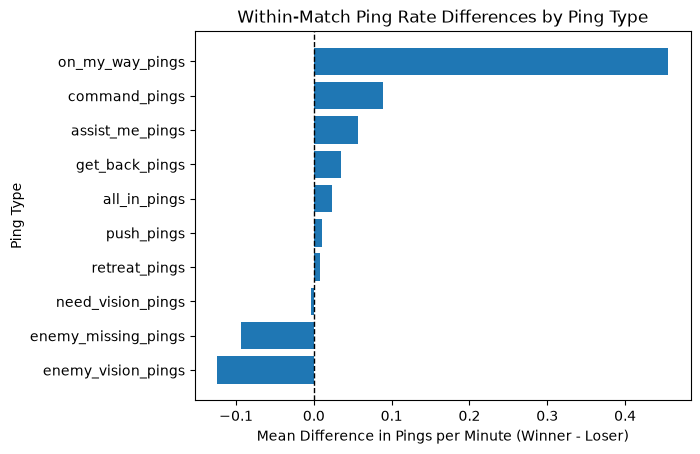

In [19]:
plot_df = (ping_type_results.sort_values("mean_difference"))

plt.barh(plot_df["ping_type"], plot_df["mean_difference"])

plt.axvline(0, color="black",linestyle="--",linewidth=1)
plt.xlabel("Mean Difference in Pings per Minute (Winner - Loser)")
plt.ylabel("Ping Type")
plt.title("Within-Match Ping Rate Differences by Ping Type")

plt.savefig(FIGURE_DIR / "01_ping_type_differences.png", dpi=300, bbox_inches="tight")

plt.show()

Positive values indicate that the ping type was used more frequently by winning teams, while negative values indicate greater use by losing teams. The largest difference is observed for `on_my_way` pings.

------------

## 3. Role-Adjusted High Ping Activity and Match Outcome

Ping frequency differs substantially across player roles, so a single global threshold may classify players from naturally higher-pinging roles as unusually active.

To account for these baseline differences, I define a role-adjusted high-ping player as someone whose ping frequency is in the top 10% among players in the same role.

I first compare win rates descriptively between role-adjusted high-ping players and other players.

In [20]:
role_high_ping_summary = (player_df.groupby("role_excessive_pinger")
    .agg(players=("win", "size"), win_rate=("win", "mean"), mean_ping_rate=("pings_per_minute","mean")))

role_high_ping_summary

,players,win_rate,mean_ping_rate
role_excessive_pinger,,,
False,10735,0.496134,0.864545
True,1195,0.534728,3.075630


In [21]:
win_rate_difference = (role_high_ping_summary.loc[True, "win_rate"] - role_high_ping_summary.loc[False, "win_rate"])

print("Win-rate difference: " f"{win_rate_difference:.4f}")

print("Percentage-point difference: " f"{win_rate_difference * 100:.2f}")

Win-rate difference: 0.0386
Percentage-point difference: 3.86


Role-adjusted high-ping players had a win rate of 53.47%, compared with 49.61% for other players, a difference of about 3.86 percentage points.

This suggests that unusually high ping activity relative to other players in the same role is positively associated with winning. However, this comparison does not account for the fact that players from the same match are not independent, so an inferential model that accounts for match-level clustering is needed.

To test whether role-adjusted high ping activity is associated with winning, I fit a logistic regression model predicting match outcome.

Player role is included as a covariate, and standard errors are clustered by `match_id` to account for dependence among players from the same match.

The model is:

**win ~ role-adjusted high ping activity + player role**

The coefficient for high ping activity is converted to an odds ratio for easier interpretation.

In [32]:
player_df["win_numeric"] = (player_df["win"].astype(int))
player_df["role_high_ping_numeric"] = (player_df["role_excessive_pinger"].astype(int))

high_ping_model = smf.logit("win_numeric ~ role_high_ping_numeric + C(team_position)", data=player_df
                           ).fit(cov_type="cluster", cov_kwds={"groups": player_df["match_id"]})
high_ping_model.summary()

Optimization terminated successfully.
         Current function value: 0.692878
         Iterations 3


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            win_numeric   No. Observations:                11930
Model:                          Logit   Df Residuals:                    11924
Method:                           MLE   Df Model:                            5
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:               0.0003877
Time:                        00:58:03   Log-Likelihood:                -8266.0
converged:                       True   LL-Null:                       -8269.2
Covariance Type:              cluster   LLR p-value:                    0.2682
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -0.0155      0.006     -2.423      0.015      -0.028      -0.003
C(team_position)[T.JUNGLE]   2.817e-16      0.001   2.07e-13      1.000      -0.003       0.003
C(team_position)[T.MIDDLE]   2.957e-16      0.001   2.19e-13      1.000      -0.003       0.003
C(team_position)[T.TOP]      2.844e-16      0.001   2.18e-13      1.000      -0.003       0.003
C(team_position)[T.UTILITY]  5.834e-16      0.001   4.38e-13      1.000      -0.003       0.003
role_high_ping_numeric          0.1546      0.063      2.438      0.015       0.030       0.279
===============================================================================================
"""

In [23]:
coef = high_ping_model.params["role_high_ping_numeric"]

se = high_ping_model.bse["role_high_ping_numeric"]

p_value = high_ping_model.pvalues["role_high_ping_numeric"]

odds_ratio = np.exp(coef)

ci = high_ping_model.conf_int().loc["role_high_ping_numeric"]

or_ci = np.exp(ci)

print(f"Coefficient: {coef:.4f}")
print(f"Clustered SE: {se:.4f}")
print(f"Odds ratio: {odds_ratio:.3f}")
print("95% CI for odds ratio: " f"[{or_ci.iloc[0]:.3f}, " f"{or_ci.iloc[1]:.3f}]")
print(f"p-value: {p_value:.6g}")

Coefficient: 0.1546
Clustered SE: 0.0634
Odds ratio: 1.167
95% CI for odds ratio: [1.031, 1.322]
p-value: 0.0147781


After accounting for player role and clustering standard errors by match, role-adjusted high ping activity remained significantly associated with winning (p = 0.015).

Players in the top 10% of ping frequency within their role had approximately 1.17 times the odds of winning compared with other players (OR = 1.167, 95% CI [1.031, 1.322]).

This is consistent with the descriptive results, where role-adjusted high-ping players had a win rate about 3.86 percentage points higher than other players.

The effect is relatively modest, and this observational analysis does not establish that increased pinging causes a higher probability of winning.

## 4. Ping Activity and Individual Performance

Exploratory analysis showed that ping frequency was associated with several individual performance measures, including KDA, kills, assists, gold, damage, and vision.

To evaluate these relationships more formally, I use regression models that include player role and cluster standard errors by match.

Because the performance measures use different scales, I standardize both ping frequency and each performance variable. This makes the coefficients comparable across outcomes.

A positive coefficient indicates that higher ping frequency is associated with a higher value of the performance measure, while a negative coefficient indicates the opposite.

In [24]:
performance_cols = [
    "kda",
    "kills_per_minute",
    "deaths_per_minute",
    "assists_per_minute",
    "gold_per_minute_calc",
    "damage_per_minute_calc",
    "vision_per_minute_calc",
    "cs_per_minute"
]

In [25]:
#standardization

analysis_df = player_df.copy()

analysis_df["ping_rate_z"] = (analysis_df["pings_per_minute"] - analysis_df["pings_per_minute"].mean()) / analysis_df["pings_per_minute"].std()

for col in performance_cols:
    analysis_df[f"{col}_z"] = (analysis_df[col] - analysis_df[col].mean()) / analysis_df[col].std()

In [26]:
#run one model for each performance measure

performance_results = []

for col in performance_cols:
    model = smf.ols(f"{col}_z ~ ping_rate_z + C(team_position)",data=analysis_df).fit(
        cov_type="cluster",
        cov_kwds={"groups": analysis_df["match_id"]})

    coef = model.params["ping_rate_z"]
    se = model.bse["ping_rate_z"]
    p = model.pvalues["ping_rate_z"]

    ci = model.conf_int().loc["ping_rate_z"]

    performance_results.append({
        "outcome": col,
        "coefficient": coef,
        "clustered_se": se,
        "ci_lower": ci.iloc[0],
        "ci_upper": ci.iloc[1],
        "p_value": p})

performance_results = pd.DataFrame(performance_results)

performance_results

,outcome,coefficient,clustered_se,ci_lower,ci_upper,p_value
0,kda,0.064577,0.010268,0.044452,0.084702,3.194458e-10
1,kills_per_minute,0.096405,0.008751,0.079254,0.113556,3.165353e-28
2,deaths_per_minute,-0.034600,0.009552,-0.053321,-0.015878,2.921367e-04
3,assists_per_minute,0.086362,0.008238,0.070216,0.102507,1.027536e-25
4,gold_per_minute_calc,0.083369,0.007551,0.068570,0.098169,2.417219e-28
5,damage_per_minute_calc,0.076833,0.008352,0.060464,0.093203,3.601550e-20
6,vision_per_minute_calc,0.071287,0.005129,0.061234,0.081340,6.522424e-44
7,cs_per_minute,0.002084,0.003920,-0.005599,0.009766,5.949949e-01


In [27]:
#correction for multiple comparisons

reject, p_adjusted, _, _ = multipletests(
    performance_results["p_value"],
    alpha=0.05,
    method="fdr_bh")

performance_results["p_adjusted"] = p_adjusted
performance_results["significant_fdr"] = reject

performance_results = (
    performance_results
    .sort_values("coefficient", ascending=False))

performance_results

,outcome,coefficient,clustered_se,ci_lower,ci_upper,p_value,p_adjusted,significant_fdr
1,kills_per_minute,0.096405,0.008751,0.079254,0.113556,3.165353e-28,8.440941e-28,True
3,assists_per_minute,0.086362,0.008238,0.070216,0.102507,1.027536e-25,2.055072e-25,True
4,gold_per_minute_calc,0.083369,0.007551,0.068570,0.098169,2.417219e-28,8.440941e-28,True
5,damage_per_minute_calc,0.076833,0.008352,0.060464,0.093203,3.601550e-20,5.762481e-20,True
6,vision_per_minute_calc,0.071287,0.005129,0.061234,0.081340,6.522424e-44,5.217939e-43,True
0,kda,0.064577,0.010268,0.044452,0.084702,3.194458e-10,4.259277e-10,True
7,cs_per_minute,0.002084,0.003920,-0.005599,0.009766,5.949949e-01,5.949949e-01,False
2,deaths_per_minute,-0.034600,0.009552,-0.053321,-0.015878,2.921367e-04,3.338705e-04,True


After accounting for player role and clustering standard errors by match, higher ping frequency was significantly associated with most individual performance measures.

The strongest positive associations were with kills per minute (β = 0.096), assists per minute (β = 0.086), and gold per minute (β = 0.083). Higher ping frequency was also positively associated with damage per minute, vision per minute, and KDA.

Deaths per minute showed a small negative association (β = -0.035), meaning that higher ping frequency was associated with slightly fewer deaths per minute.

CS per minute was the only performance measure that was not significantly associated with ping frequency after accounting for role (adjusted p = 0.595).

Although most relationships were statistically significant, the standardized coefficients were relatively small. Overall, the results do not support the idea that higher ping frequency is associated with worse individual performance.

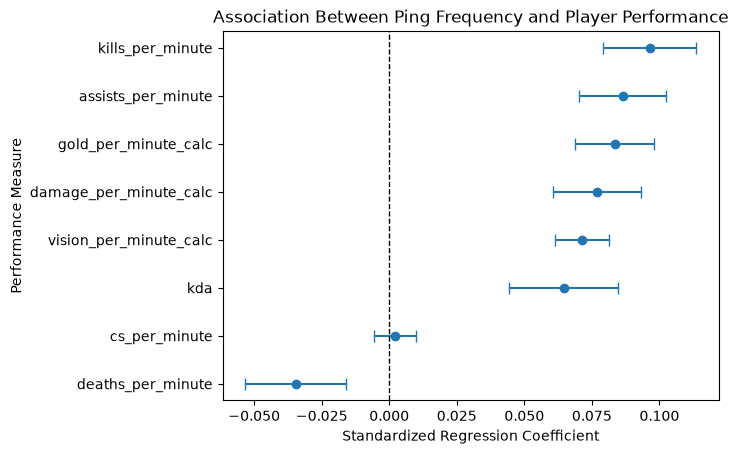

In [28]:
plot_df = (performance_results.sort_values("coefficient"))


plt.errorbar(
    plot_df["coefficient"],
    plot_df["outcome"],
    xerr=[plot_df["coefficient"] - plot_df["ci_lower"], plot_df["ci_upper"] - plot_df["coefficient"]],
    fmt="o",
    capsize=4)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("Standardized Regression Coefficient")
plt.ylabel("Performance Measure")
plt.title("Association Between Ping Frequency and Player Performance")

plt.savefig(FIGURE_DIR / "01_ping_type_differences.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURE_DIR / "02_ping_performance_coefficients.png", dpi=300, bbox_inches="tight")

plt.show()

The coefficients are standardized, so they can be compared across performance measures. Most associations are positive but relatively small, while the confidence interval for CS per minute crosses zero.

--------------------

## 5. Ping Composition and Match Outcome

The previous analysis compared the absolute frequency of each ping type. However, teams that ping more overall may naturally use more of many individual ping types.

To examine the composition of ping behavior, I calculate each ping type as a share of the team's total active pings.

For each match, I then compare the winning and losing team's ping-type shares using paired Wilcoxon signed-rank tests. P-values are adjusted using the Benjamini-Hochberg procedure.

Because ping shares sum to 1 within each team, these variables are not independent of one another. The results are therefore interpreted as descriptive differences in communication composition rather than independent effects of each ping type.

In [31]:
team_ping_types["team_total_active_pings"] = team_ping_types[[f"team_{col}" for col in ping_cols]].sum(axis=1)

for col in ping_cols:
    team_ping_types[f"{col}_share"] = team_ping_types[f"team_{col}"]/team_ping_types["team_total_active_pings"]

In [38]:
#validation check

(team_ping_types["team_total_active_pings"] == 0).sum()

np.int64(0)

All teams recorded at least one active ping, so ping shares can be calculated without division by zero.

For each ping type, I compare its share of total ping activity between the winning and losing teams in the same match.

A positive difference means that the ping type makes up a larger proportion of the winning team's pings. A negative difference means that it makes up a larger proportion of the losing team's pings.

In [42]:
ping_share_results = []

for col in ping_cols:
    share_col = f"{col}_share"

    paired = (
        team_ping_types.pivot(
            index="match_id",
            columns="team_win",
            values=share_col)
        .rename(columns={False: "loss", True: "win"})
        .dropna())

    paired["difference"] = paired["win"] - paired["loss"]
    
    #skip ping types with no differences
    if (paired["difference"] != 0).sum() == 0:
        continue

    stat, p = stats.wilcoxon(paired["win"], paired["loss"], alternative="two-sided")
    

    ping_share_results.append({
        "ping_type": col,
        "winner_mean_share": paired["win"].mean(),
        "loser_mean_share": paired["loss"].mean(),
        "mean_difference": paired["difference"].mean(),
        "median_difference": paired["difference"].median(),
        "p_value": p})

ping_share_results = pd.DataFrame(ping_share_results)
ping_share_results.sort_values("p_value")

,ping_type,winner_mean_share,loser_mean_share,mean_difference,median_difference,p_value
7,on_my_way_pings,0.313974,0.252316,0.061658,0.063535,7.469256e-46
3,enemy_missing_pings,0.149267,0.182741,-0.033474,-0.032349,2.181952e-27
4,enemy_vision_pings,0.078893,0.109598,-0.030704,-0.019062,1.662956e-18
8,push_pings,0.013734,0.012539,0.001195,0.000000,3.015599e-04
0,all_in_pings,0.018420,0.015719,0.002701,0.000000,5.246886e-04
9,retreat_pings,0.072310,0.077244,-0.004935,0.000000,1.196865e-01
2,command_pings,0.184081,0.181318,0.002763,0.005175,2.859000e-01
1,assist_me_pings,0.100777,0.098405,0.002373,0.003322,2.976023e-01
6,need_vision_pings,0.008668,0.009893,-0.001225,0.000000,5.606513e-01
5,get_back_pings,0.059875,0.060227,-0.000353,-0.000337,6.474790e-01


In [43]:
reject, p_adjusted, _, _ = multipletests(
    ping_share_results["p_value"],
    alpha=0.05,
    method="fdr_bh")

ping_share_results["p_adjusted"] = p_adjusted
ping_share_results["significant_fdr"] = reject

ping_share_results = ping_share_results.sort_values("p_adjusted")

ping_share_results[["ping_type", "winner_mean_share", "loser_mean_share", "mean_difference", "median_difference", "p_value", "p_adjusted", "significant_fdr"]]

,ping_type,winner_mean_share,loser_mean_share,mean_difference,median_difference,p_value,p_adjusted,significant_fdr
7,on_my_way_pings,0.313974,0.252316,0.061658,0.063535,7.469256e-46,7.469256e-45,True
3,enemy_missing_pings,0.149267,0.182741,-0.033474,-0.032349,2.181952e-27,1.090976e-26,True
4,enemy_vision_pings,0.078893,0.109598,-0.030704,-0.019062,1.662956e-18,5.543187e-18,True
8,push_pings,0.013734,0.012539,0.001195,0.000000,3.015599e-04,7.538997e-04,True
0,all_in_pings,0.018420,0.015719,0.002701,0.000000,5.246886e-04,1.049377e-03,True
9,retreat_pings,0.072310,0.077244,-0.004935,0.000000,1.196865e-01,1.994775e-01,False
2,command_pings,0.184081,0.181318,0.002763,0.005175,2.859000e-01,3.720028e-01,False
1,assist_me_pings,0.100777,0.098405,0.002373,0.003322,2.976023e-01,3.720028e-01,False
6,need_vision_pings,0.008668,0.009893,-0.001225,0.000000,5.606513e-01,6.229458e-01,False
5,get_back_pings,0.059875,0.060227,-0.000353,-0.000337,6.474790e-01,6.474790e-01,False


After adjusting for multiple comparisons, 5 of the 10 ping types showed statistically significant differences in their share of total team ping activity.

The largest difference was for on_my_way pings, which accounted for 31.40% of winning teams' pings compared with 25.23% of losing teams' pings, a difference of 6.17 percentage points.

In contrast, enemy_missing and enemy_vision pings made up larger shares of losing teams' ping activity, with differences of approximately 3.35 and 3.07 percentage points, respectively.

push and all_in pings were also statistically significant, but their differences were relatively small. The remaining five ping types did not show significant differences after FDR correction.

These findings suggest that ping composition differs between winning and losing teams, even after accounting for differences in overall ping volume. However, ping shares are interdependent because they sum to 100%, and these results do not establish whether particular ping types contribute to winning or simply reflect differences in game situations.

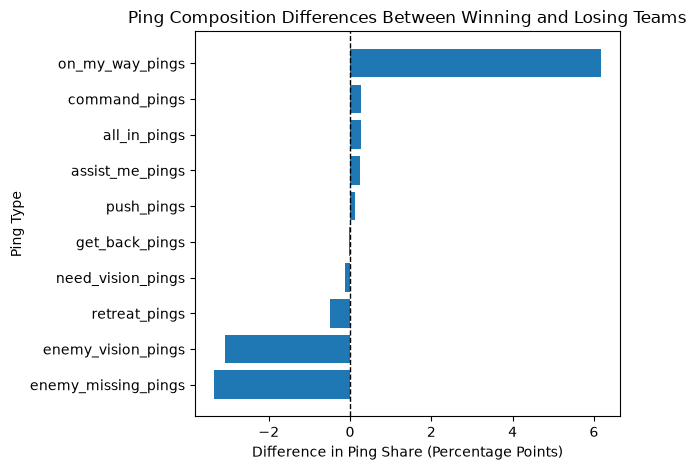

In [46]:
plot_df = (ping_share_results.sort_values("mean_difference").copy())

plot_df["difference_pp"] = plot_df["mean_difference"] * 100

plt.barh(plot_df["ping_type"], plot_df["difference_pp"])

plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Difference in Ping Share (Percentage Points)")
plt.ylabel("Ping Type")
plt.title("Ping Composition Differences Between Winning and Losing Teams")

plt.tight_layout()

plt.savefig(FIGURE_DIR / "ping_share_differences.png", dpi=300, bbox_inches="tight")

The largest difference is for on_my_way pings, which make up a greater share of winning teams' communication. enemy_missing and enemy_vision pings make up greater shares of losing teams' communication. Most other ping types show relatively small differences.

on_my_way_pings skewness: -0.033
enemy_missing_pings skewness: 0.017
enemy_vision_pings skewness: -0.89


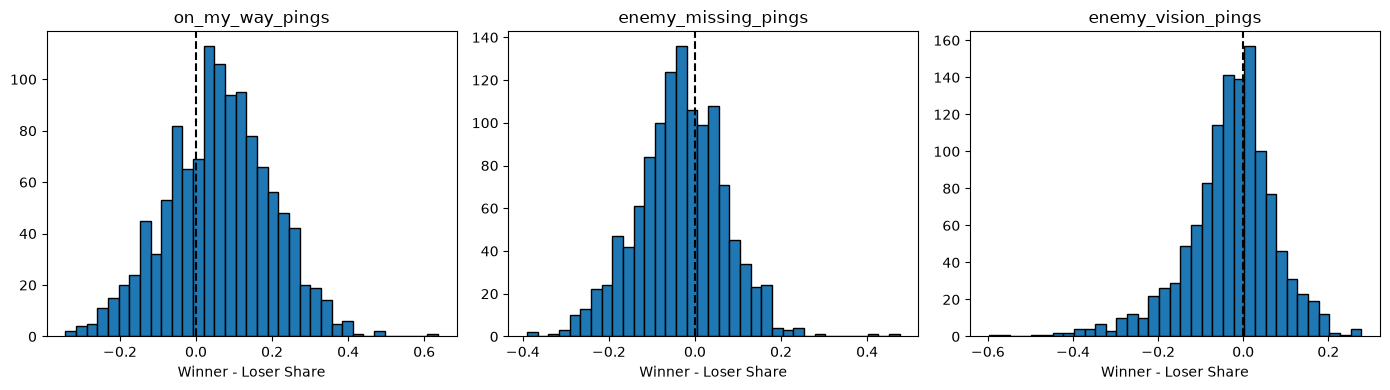

In [53]:
#check symmetry of paired differences for the three main ping types
#Wilcoxon does not require normality, but assumes symmetric differences

main_ping_types = ["on_my_way_pings", "enemy_missing_pings", "enemy_vision_pings"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, main_ping_types):
    paired = (
        team_ping_types.pivot(
            index="match_id",
            columns="team_win",
            values=f"{col}_share")
        .dropna())

    differences = paired[True] - paired[False]

    ax.hist(differences, bins=35, edgecolor="black")
    
    ax.axvline(0, color="black", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("Winner - Loser Share")

    print(col, "skewness:", round(differences.skew(), 3))

plt.tight_layout()
plt.show()

The paired differences for on_my_way and enemy_missing were approximately symmetric, with skewness values of -0.033 and 0.017. The differences for enemy_vision were more negatively skewed (-0.890), so I also used a sign test to check whether the result remained significant without assuming symmetry.

The sign test was statistically significant (p < 0.001). Losing teams had a larger enemy_vision ping share in 701 matches, compared with 489 matches where winning teams had a larger share. This supports the earlier finding that enemy_vision pings make up a greater share of losing teams' communication.

This result is particularly relevant to my original hypothesis about potentially disruptive ping behavior. Although the pattern could be consistent with disruptive pinging, it could also reflect legitimate communication during unfavorable game situations. Since the dataset does not measure player intent, I cannot determine whether these pings were toxic.

The paired differences for `on_my_way` and `enemy_missing` ping shares were approximately symmetric, with skewness values of -0.033 and 0.017, respectively.

The differences for `enemy_vision` were more negatively skewed (-0.890), so I also used a paired sign test as a robustness check.

This helps determine whether the `enemy_vision` finding remains supported without relying on the symmetry assumption of the Wilcoxon signed-rank test.

In [52]:
#sign test for enemy_vision ping shares

paired = (
    team_ping_types.pivot(
        index="match_id",
        columns="team_win",
        values="enemy_vision_pings_share")
    .dropna())

differences = paired[True] - paired[False]

positive = (differences > 0).sum()
negative = (differences < 0).sum()

result = stats.binomtest(positive, n=positive + negative, p=0.5, alternative="two-sided")

print("Positive differences:", positive)
print("Negative differences:", negative)
print("Ties:", (differences == 0).sum())
print("Sign test p-value:", result.pvalue)

Positive differences: 489
Negative differences: 701
Ties: 3
Sign test p-value: 8.658439976984861e-10


The sign test was statistically significant (p < 0.001). Losing teams had a larger enemy_vision ping share in 701 matches, compared with 489 matches where winning teams had a larger share. This supports the earlier finding that enemy_vision pings make up a greater share of losing teams' communication.

This finding is particularly relevant to my original hypothesis about potentially disruptive ping behavior.

------------

## 6. Unusually High Enemy Ping Activity

The previous analysis showed that `enemy_missing` and `enemy_vision` pings made up larger shares of losing teams' communication.

To investigate whether unusually frequent use of these pings is associated with worse outcomes, I examine both ping types at the individual-player level.

I define unusually high usage as being above the 95th percentile of pings per minute within the same role. This accounts for differences in baseline ping frequency across player positions.

These ping types may sometimes be used disruptively, but the dataset does not measure player intent, so unusually frequent usage cannot be treated as direct evidence of toxicity.

### 6.1 High Ping Usage and Win Rates

In [67]:
#calculate 95th percentile within each role

enemy_ping_types = ["enemy_missing", "enemy_vision"]

for ping in enemy_ping_types:
    rate_col = f"{ping}_pings_per_minute"

    threshold = player_df.groupby("team_position")[rate_col].transform(lambda x: x.quantile(0.95))
    
    player_df[f"high_{ping}"] = player_df[rate_col] > threshold

player_df[["high_enemy_missing", "high_enemy_vision"]].sum()

high_enemy_missing    599
high_enemy_vision     600
dtype: int64

In [68]:
win_rate_results = []

for ping in enemy_ping_types:
    high_col = f"high_{ping}"

    summary = player_df.groupby(high_col)["win"].agg(["size", "mean"])

    win_rate_results.append({
        "ping_type": ping,
        "high_usage_players": summary.loc[True, "size"],
        "high_usage_win_rate": summary.loc[True, "mean"],
        "other_win_rate": summary.loc[False, "mean"],
        "difference_pp": (summary.loc[True, "mean"] - summary.loc[False, "mean"]) * 100})

win_rate_results = pd.DataFrame(win_rate_results)
win_rate_results

,ping_type,high_usage_players,high_usage_win_rate,other_win_rate,difference_pp
0,enemy_missing,599,0.415693,0.504457,-8.876398
1,enemy_vision,600,0.396667,0.505472,-10.880553


In [58]:
win_rate_difference = enemy_vision_summary.loc[True, "win_rate"] - enemy_vision_summary.loc[False, "win_rate"]

print(f"Win-rate difference: {win_rate_difference:.4f}")
print(f"Percentage-point difference: {win_rate_difference * 100:.2f}")

Win-rate difference: -0.1088
Percentage-point difference: -10.88


Players with unusually high `enemy_missing` and `enemy_vision` ping frequency had lower win rates than other players.

High `enemy_missing` users had a win rate of 41.57%, compared with 50.45% for other players. High `enemy_vision` users had a win rate of 39.67%, compared with 50.55%.

Both ping types show negative descriptive associations with winning, unlike the positive association observed for overall ping frequency.

### 6.3 Logistic Regression
To test whether unusually high usage of either ping type is associated with winning, I fit separate logistic regression models for `enemy_missing` and `enemy_vision`.

Each model includes player role as a covariate, and standard errors are clustered by match to account for dependence among players in the same game.

I use two-sided tests because unusually high ping activity could be associated with either higher or lower odds of winning.

In [70]:
logit_results = []

for ping in enemy_ping_types:
    high_col = f"high_{ping}"
    numeric_col = f"{high_col}_numeric"

    player_df[numeric_col] = player_df[high_col].astype(int)

    model = (smf.logit(
        f"win_numeric ~ {numeric_col} + C(team_position)",
        data=player_df)
        .fit(cov_type="cluster", cov_kwds={"groups": player_df["match_id"]}, disp=False))

    coef = model.params[numeric_col]
    ci = model.conf_int().loc[numeric_col]

    logit_results.append({
        "ping_type": ping,
        "coefficient": coef,
        "clustered_se": model.bse[numeric_col],
        "odds_ratio": np.exp(coef),
        "ci_lower": np.exp(ci.iloc[0]),
        "ci_upper": np.exp(ci.iloc[1]),
        "p_value": model.pvalues[numeric_col]})

logit_results = pd.DataFrame(logit_results)
logit_results

,ping_type,coefficient,clustered_se,odds_ratio,ci_lower,ci_upper,p_value
0,enemy_missing,-0.358308,0.086802,0.698858,0.589526,0.828466,3.661062e-05
1,enemy_vision,-0.441263,0.089011,0.643223,0.540251,0.765822,7.143525e-07


In [71]:
#since we're testing two ping types we adjust the p-values using Benjamini-Hochberg

reject, p_adjusted, _, _ = multipletests(logit_results["p_value"], alpha=0.05,method="fdr_bh")

logit_results["p_adjusted"] = p_adjusted
logit_results["significant_fdr"] = reject

logit_results

,ping_type,coefficient,clustered_se,odds_ratio,ci_lower,ci_upper,p_value,p_adjusted,significant_fdr
0,enemy_missing,-0.358308,0.086802,0.698858,0.589526,0.828466,3.661062e-05,0.000037,True
1,enemy_vision,-0.441263,0.089011,0.643223,0.540251,0.765822,7.143525e-07,0.000001,True


Both enemy_missing and enemy_vision showed statistically significant negative associations with winning after accounting for player role and clustering standard errors by match (adjusted p < 0.001 for both).

Players with unusually high enemy_missing usage had approximately 30.1% lower odds of winning (OR = 0.699, 95% CI [0.590, 0.828]). Players with unusually high enemy_vision usage had approximately 35.7% lower odds of winning (OR = 0.643, 95% CI [0.540, 0.766]).

These findings contrast with the earlier positive association between overall ping frequency and winning. They suggest that unusually frequent use of certain ping types may be associated with worse outcomes, although the data cannot establish whether this reflects disruptive behavior or reactions to unfavorable game situations.

### 6.3 Individual Performance
To investigate whether unusually high `enemy_missing` and `enemy_vision` usage is also associated with individual performance, I compare KDA, deaths per minute, and assists per minute.

I use linear regression models that include player role and cluster standard errors by match.

I also fit models that account for match outcome to examine whether the associations remain when comparing players with the same win/loss result. Because all variables are measured over the full match, these comparisons do not establish causality.

In [72]:
performance_cols = ["kda", "deaths_per_minute","assists_per_minute"]

performance_df = player_df.copy()

for col in performance_cols:
    performance_df[f"{col}_z"] = (performance_df[col] - performance_df[col].mean())/performance_df[col].std()

In [73]:
enemy_performance_results = []

for ping in enemy_ping_types:
    high_col = f"high_{ping}_numeric"

    for col in performance_cols:
        for adjust_for_win in [False, True]:
            formula = f"{col}_z ~ {high_col} + C(team_position)"

            if adjust_for_win:
                formula += " + win_numeric"

            model = (smf.ols(
                formula,
                data=performance_df)
                .fit(cov_type="cluster", cov_kwds={"groups": performance_df["match_id"]}))

            ci = model.conf_int().loc[high_col]

            enemy_performance_results.append({
                "ping_type": ping,
                "outcome": col,
                "adjusted_for_win": adjust_for_win,
                "coefficient": model.params[high_col],
                "ci_lower": ci.iloc[0],
                "ci_upper": ci.iloc[1],
                "p_value": model.pvalues[high_col]})

enemy_performance_results = pd.DataFrame(enemy_performance_results)

In [74]:
for adjusted in [False, True]:
    mask = enemy_performance_results["adjusted_for_win"] == adjusted

    reject, p_adjusted, _, _ = multipletests(
        enemy_performance_results.loc[mask, "p_value"],
        alpha=0.05,
        method="fdr_bh")

    enemy_performance_results.loc[mask, "p_adjusted"] = p_adjusted
    enemy_performance_results.loc[mask, "significant_fdr"] = reject

In [77]:
print("Without adjusting for match outcome:")
display(enemy_performance_results[~enemy_performance_results["adjusted_for_win"]])

print("Adjusting for match outcome:")
display(enemy_performance_results[enemy_performance_results["adjusted_for_win"]])

Without adjusting for match outcome:


,ping_type,outcome,adjusted_for_win,coefficient,ci_lower,ci_upper,p_value,p_adjusted,significant_fdr
0,enemy_missing,kda,False,-0.131319,-0.200249,-0.062388,1.885534e-04,2.828302e-04,True
2,enemy_missing,deaths_per_minute,False,0.043111,-0.038778,0.125000,3.021500e-01,3.021500e-01,False
4,enemy_missing,assists_per_minute,False,-0.095798,-0.164208,-0.027388,6.058008e-03,7.269610e-03,True
6,enemy_vision,kda,False,-0.204554,-0.271981,-0.137127,2.748221e-09,1.648932e-08,True
8,enemy_vision,deaths_per_minute,False,0.212710,0.128045,0.297374,8.472080e-07,2.541624e-06,True
10,enemy_vision,assists_per_minute,False,-0.153309,-0.217299,-0.089319,2.656633e-06,5.313266e-06,True


Adjusting for match outcome:


,ping_type,outcome,adjusted_for_win,coefficient,ci_lower,ci_upper,p_value,p_adjusted,significant_fdr
1,enemy_missing,kda,True,-0.047610,-0.105861,0.010641,0.109172,0.163759,False
3,enemy_missing,deaths_per_minute,True,-0.038160,-0.111202,0.034881,0.305845,0.305845,False
5,enemy_missing,assists_per_minute,True,-0.033512,-0.095511,0.028486,0.289403,0.305845,False
7,enemy_vision,kda,True,-0.102089,-0.159568,-0.044609,0.000499,0.002997,True
9,enemy_vision,deaths_per_minute,True,0.113415,0.036843,0.189987,0.003696,0.011088,True
11,enemy_vision,assists_per_minute,True,-0.077073,-0.133018,-0.021128,0.006930,0.013861,True


Without adjusting for match outcome, unusually high enemy_missing usage was associated with lower KDA and fewer assists per minute, but not significantly more deaths per minute. Unusually high enemy_vision usage was associated with lower KDA, more deaths per minute, and fewer assists per minute. All significant results remained significant after correcting for multiple comparisons.

After accounting for match outcome, none of the individual performance associations for enemy_missing remained statistically significant. In contrast, high enemy_vision usage remained associated with lower KDA (β = -0.102), more deaths per minute (β = 0.113), and fewer assists per minute (β = -0.077), with adjusted p-values below 0.05.

These results suggest that the two ping types may reflect different patterns. Although unusually high usage of both ping types was associated with lower win rates, high enemy_vision usage showed a more consistent negative association with individual performance. However, the data cannot determine whether these pings contribute to poor performance or are responses to difficult game situations.

-----

## 7. Conclusion

The statistical analysis found that higher overall ping frequency was associated with winning and several positive individual performance measures. Winning teams pinged more frequently than losing teams within the same match, and players with unusually high overall ping activity had slightly higher odds of winning after accounting for player role and clustering by match.

However, the results differed substantially across ping types. on_my_way pings were more common among winning teams, both in frequency and as a share of total pings. In contrast, enemy_missing and enemy_vision pings accounted for larger shares of losing teams' communication.

At the individual level, players with unusually high enemy_missing and enemy_vision ping activity had significantly lower odds of winning (OR = 0.699 and OR = 0.643, respectively). Both associations remained statistically significant after correcting for multiple comparisons.

The individual performance analysis revealed an additional difference. High enemy_missing usage was associated with lower KDA and fewer assists per minute, but these associations were no longer statistically significant after accounting for match outcome. High enemy_vision usage, however, remained associated with lower KDA, more deaths per minute, and fewer assists per minute even after accounting for match outcome.

Overall, these findings suggest that ping type and usage patterns may be more informative than total ping frequency alone. The positive association between overall ping activity and winning contrasts with the negative associations observed for unusually frequent enemy_missing and enemy_vision usage.

However, the data only records ping counts over entire matches, not player intent or when individual pings occurred. It is therefore not possible to determine whether high ping activity reflects disruptive behavior, legitimate communication, or reactions to unfavorable game situations. These findings support further investigation into how specific communication patterns relate to player performance, but do not establish that excessive pinging causes poor outcomes.